In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Current folder:", Path.cwd())

dataset_name = "MobiAct_Dataset_v2.0-MobiFall_Dataset_v2.0"

possible_paths = [
    Path("data/raw") / dataset_name,
    Path("../data/raw") / dataset_name,
]

DATASET_DIR = None

for path in possible_paths:
    if path.exists():
        DATASET_DIR = path
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Dataset folder not found. Please check your data/raw folder.")

print("Dataset found:", DATASET_DIR)

TensorFlow version: 2.21.0
Current folder: /Users/zichen/fall_detection_project/notebooks
Dataset found: ../data/raw/MobiAct_Dataset_v2.0-MobiFall_Dataset_v2.0


In [2]:
# Normal daily activities
ADL_CODES = {
    "STD",  # standing
    "WAL",  # walking
    "JOG",  # jogging
    "JUM",  # jumping
    "STU",  # stairs up
    "STN",  # stairs down
    "SCH",  # sitting chair
    "CSI",  # car step in
    "CSO"   # car step out
}

# Fall activities
FALL_CODES = {
    "FOL",  # forward lying
    "FKL",  # front knees lying
    "BSC",  # back sitting chair
    "SDL"   # sideward lying
}

WINDOW_SIZE = 128
STEP_SIZE = 64

print("Labels ready")

Labels ready


In [3]:
def read_sensor_file(file_path):
    rows = []

    with open(file_path, "r", errors="ignore") as f:
        for line in f:
            parts = re.split(r"[,\s;]+", line.strip())

            if len(parts) < 4:
                continue

            try:
                nums = [float(x) for x in parts[:4]]
                rows.append(nums)
            except:
                continue

    return pd.DataFrame(rows, columns=["timestamp", "x", "y", "z"])


def parse_filename(file_path):
    parts = file_path.stem.split("_")

    if len(parts) != 4:
        return None

    activity, sensor, subject, trial = parts

    if sensor not in ["acc", "gyro"]:
        return None

    return activity, sensor, subject, trial


samples = {}

for file_path in DATASET_DIR.rglob("*.txt"):
    parsed = parse_filename(file_path)

    if parsed is None:
        continue

    activity, sensor, subject, trial = parsed
    key = (activity, subject, trial)

    if key not in samples:
        samples[key] = {}

    samples[key][sensor] = file_path

print("Total sample groups found:", len(samples))

Total sample groups found: 630


In [4]:
X = []
y = []
subjects = []

for key, sensor_files in samples.items():
    activity, subject, trial = key

    # Need both accelerometer and gyroscope
    if "acc" not in sensor_files or "gyro" not in sensor_files:
        continue

    acc_df = read_sensor_file(sensor_files["acc"])
    gyro_df = read_sensor_file(sensor_files["gyro"])

    min_len = min(len(acc_df), len(gyro_df))

    if min_len < WINDOW_SIZE:
        continue

    acc_values = acc_df[["x", "y", "z"]].values[:min_len]
    gyro_values = gyro_df[["x", "y", "z"]].values[:min_len]

    # Combine acc + gyro = 6 features
    combined = np.concatenate([acc_values, gyro_values], axis=1)

    if activity in FALL_CODES:
        label = 1   # fall
    elif activity in ADL_CODES:
        label = 0   # normal
    else:
        continue

    for start in range(0, len(combined) - WINDOW_SIZE + 1, STEP_SIZE):
        end = start + WINDOW_SIZE

        X.append(combined[start:end])
        y.append(label)
        subjects.append(subject)

X = np.array(X)
y = np.array(y)
subjects = np.array(subjects)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Normal windows:", np.sum(y == 0))
print("Fall windows:", np.sum(y == 1))
print("Total subjects:", len(np.unique(subjects)))

X shape: (15375, 128, 6)
y shape: (15375,)
Normal windows: 12032
Fall windows: 3343
Total subjects: 24


In [5]:
splitter = GroupShuffleSplit(
    n_splits=20,
    test_size=0.2,
    random_state=42
)

for train_idx, test_idx in splitter.split(X, y, groups=subjects):
    y_train_check = y[train_idx]
    y_test_check = y[test_idx]

    if len(np.unique(y_train_check)) == 2 and len(np.unique(y_test_check)) == 2:
        break

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Train windows:", X_train.shape[0])
print("Test windows:", X_test.shape[0])
print("Train normal:", np.sum(y_train == 0))
print("Train fall:", np.sum(y_train == 1))
print("Test normal:", np.sum(y_test == 0))
print("Test fall:", np.sum(y_test == 1))

# Normalize data
scaler = StandardScaler()

X_train_2d = X_train.reshape(-1, X_train.shape[-1])
X_test_2d = X_test.reshape(-1, X_test.shape[-1])

scaler.fit(X_train_2d)

X_train_scaled = scaler.transform(X_train_2d).reshape(X_train.shape)
X_test_scaled = scaler.transform(X_test_2d).reshape(X_test.shape)

print("Data normalization completed")

Train windows: 12035
Test windows: 3340
Train normal: 9368
Train fall: 2667
Test normal: 2664
Test fall: 676
Data normalization completed


In [6]:
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:", class_weight)

model = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 6)),

    layers.Conv1D(32, kernel_size=5, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=5, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),

    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    verbose=1
)

Class weights: {0: np.float64(0.6423462852263023), 1: np.float64(2.256280464941882)}
Epoch 1/20
301/301 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9266 - loss: 0.1939 - precision: 0.7107 - recall: 0.9358 - val_accuracy: 0.9435 - val_loss: 0.1565 - val_precision: 0.9370 - val_recall: 0.9370
Epoch 2/20
301/301 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9461 - loss: 0.1326 - precision: 0.7695 - recall: 0.9610 - val_accuracy: 0.9514 - val_loss: 0.1291 - val_precision: 0.9389 - val_recall: 0.9537
Epoch 3/20
301/301 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9497 - loss: 0.1139 - precision: 0.7808 - recall: 0.9666 - val_accuracy: 0.9568 - val_loss: 0.1157 - val_precision: 0.9380 - val_recall: 0.9676
Epoch 4/20
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9532 - loss: 0.0954 - precision: 0.7893 - recall: 0.9767 - val_accuracy: 0.9468 - val_loss: 0.1568 - val_precision: 0.9542 - val_recall: 0.9259
Epoch 5/20
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9575 -

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import pandas as pd

# Predict fall probability
y_prob = model.predict(X_test_scaled).ravel()

# Selected threshold
BEST_THRESHOLD = 0.40

# Convert probability to class label
y_pred = (y_prob >= BEST_THRESHOLD).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
fall_precision = precision_score(y_test, y_pred)
fall_recall = recall_score(y_test, y_pred)
fall_f1 = f1_score(y_test, y_pred)

print("===== FINAL CNN MODEL RESULT =====")
print(f"Threshold Used : {BEST_THRESHOLD}")
print(f"Accuracy       : {accuracy * 100:.2f}%")
print(f"Fall Precision : {fall_precision * 100:.2f}%")
print(f"Fall Recall    : {fall_recall * 100:.2f}%")
print(f"Fall F1-score  : {fall_f1 * 100:.2f}%")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Normal", "Actual Fall"],
    columns=["Predicted Normal", "Predicted Fall"]
)

print("\nConfusion Matrix:")
print(cm_df)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fall"]
))

105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
===== FINAL CNN MODEL RESULT =====
Threshold Used : 0.4
Accuracy       : 94.34%
Fall Precision : 82.86%
Fall Recall    : 90.83%
Fall F1-score  : 86.66%

Confusion Matrix:
               Predicted Normal  Predicted Fall
Actual Normal              2537             127
Actual Fall                  62             614

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.95      0.96      2664
        Fall       0.83      0.91      0.87       676

    accuracy                           0.94      3340
   macro avg       0.90      0.93      0.92      3340
weighted avg       0.95      0.94      0.94      3340



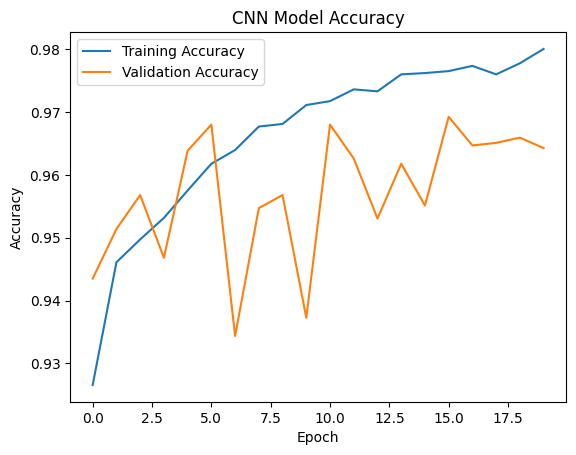

In [8]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()